In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

try:
    btc_df = pd.read_csv("glassnode/glassnode_BTC_tier1.csv", index_col=0)
    eth_df = pd.read_csv("glassnode/glassnode_ETH_tier1.csv", index_col=0)
    
except FileNotFoundError:
    print("파일 없음. glassnode_request.py 실행.")
    
    import subprocess
    subprocess.run(["python", "glassnode_request.py"])

    btc_df = pd.read_csv("glassnode/glassnode_BTC_tier1.csv", index_col=0)
    eth_df = pd.read_csv("glassnode/glassnode_ETH_tier1.csv", index_col=0)

In [2]:
# ETH 데이터프레임 복사본 생성
eth_temp = eth_df.copy()

# 컬럼 유형별 분류
rel_change_col = ["price_drawdown_relative",]  # 상대적 변화율 컬럼
pct_change_col = ["rate", "staking_phase_0_goal_percent",]  # 퍼센트 변화율 컬럼
nominal_col = eth_temp.columns[~eth_temp.columns.isin(rel_change_col + pct_change_col)]  # 명목값 컬럼

# price_drawdown_relative 값을 양수로 변환 (하락폭을 상승폭으로 해석)
eth_temp['price_drawdown_relative'] = eth_temp['price_drawdown_relative'] * (-1)
# 상대적 변화율 컬럼에 대해 차분 계산
eth_temp[rel_change_col] = eth_temp[rel_change_col].diff(1)
# 퍼센트 컬럼을 소수점으로 변환 후 차분 계산
eth_temp[pct_change_col] = (eth_temp[pct_change_col]/100).diff(1)

# 명목값 컬럼에 대해 로그 수익률 계산
eth_temp[nominal_col] = np.log(eth_temp[nominal_col]/eth_temp[nominal_col].shift(1))
# NA값이 있는 컬럼 제거하고 복사
full_eth = eth_temp.loc[:, ~eth_temp.iloc[1:].isna().any(axis=0)].copy()
# 첫 행 제거 (차분 계산으로 인한 NA 제거)
full_eth = full_eth.iloc[1:]

# BTC 데이터프레임에 대해서도 동일한 처리
btc_temp = btc_df.copy()
btc_temp = btc_temp.astype(float)  # 모든 값을 float 타입으로 변환

# 컬럼 유형별 분류
rel_change_col = ["price_drawdown_relative",]
pct_change_col = ["rate",]
nominal_col = btc_temp.columns[~btc_temp.columns.isin(rel_change_col + pct_change_col)]
nominal_col = btc_temp.columns  # 모든 컬럼을 명목값으로 처리

# ETH와 동일한 전처리 과정 수행
btc_temp['price_drawdown_relative'] = btc_temp['price_drawdown_relative'] * (-1)
btc_temp[rel_change_col] = btc_temp[rel_change_col].diff(1)
btc_temp[pct_change_col] = (btc_temp[pct_change_col]/100).diff(1)

btc_temp[nominal_col] = np.log(btc_temp[nominal_col]/btc_temp[nominal_col].shift(1))
full_btc = btc_temp.loc[:, ~btc_temp.iloc[1:].isna().any(axis=0)].copy()
full_btc = full_btc.iloc[1:]

c:\Users\wklee\Desktop\WKLee\FBA\Capstone\fba-capstone\.venv\Lib\site-packages\pandas\core\internals\blocks.py:393: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)
c:\Users\wklee\Desktop\WKLee\FBA\Capstone\fba-capstone\.venv\Lib\site-packages\pandas\core\internals\blocks.py:393: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)
c:\Users\wklee\Desktop\WKLee\FBA\Capstone\fba-capstone\.venv\Lib\site-packages\pandas\core\internals\blocks.py:393: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)


### 해야할 것 - 온체인 데이터 중 중요한 변수 찾기. 

Trend가 up이냐, down이냐로 나누어진 두 그룹에서의 온체인 데이터 분포가 다른지 확인.
KS-test를 이용해 두 분포가 다른지 가설 검정.  

위에서 unit 단위의 데이터를 차분해 변화율로 변환함.  
이를 다시 정규화해 z-score로 변환함.  
이를 히스토그램으로 시각화해 분포 확인.  

C:\Users\wklee\AppData\Local\Temp\ipykernel_16912\837506596.py:15: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  pd.DataFrame(z_scores, columns=btc_df_numeric.columns).hist(ax=axes[1], bins=50)


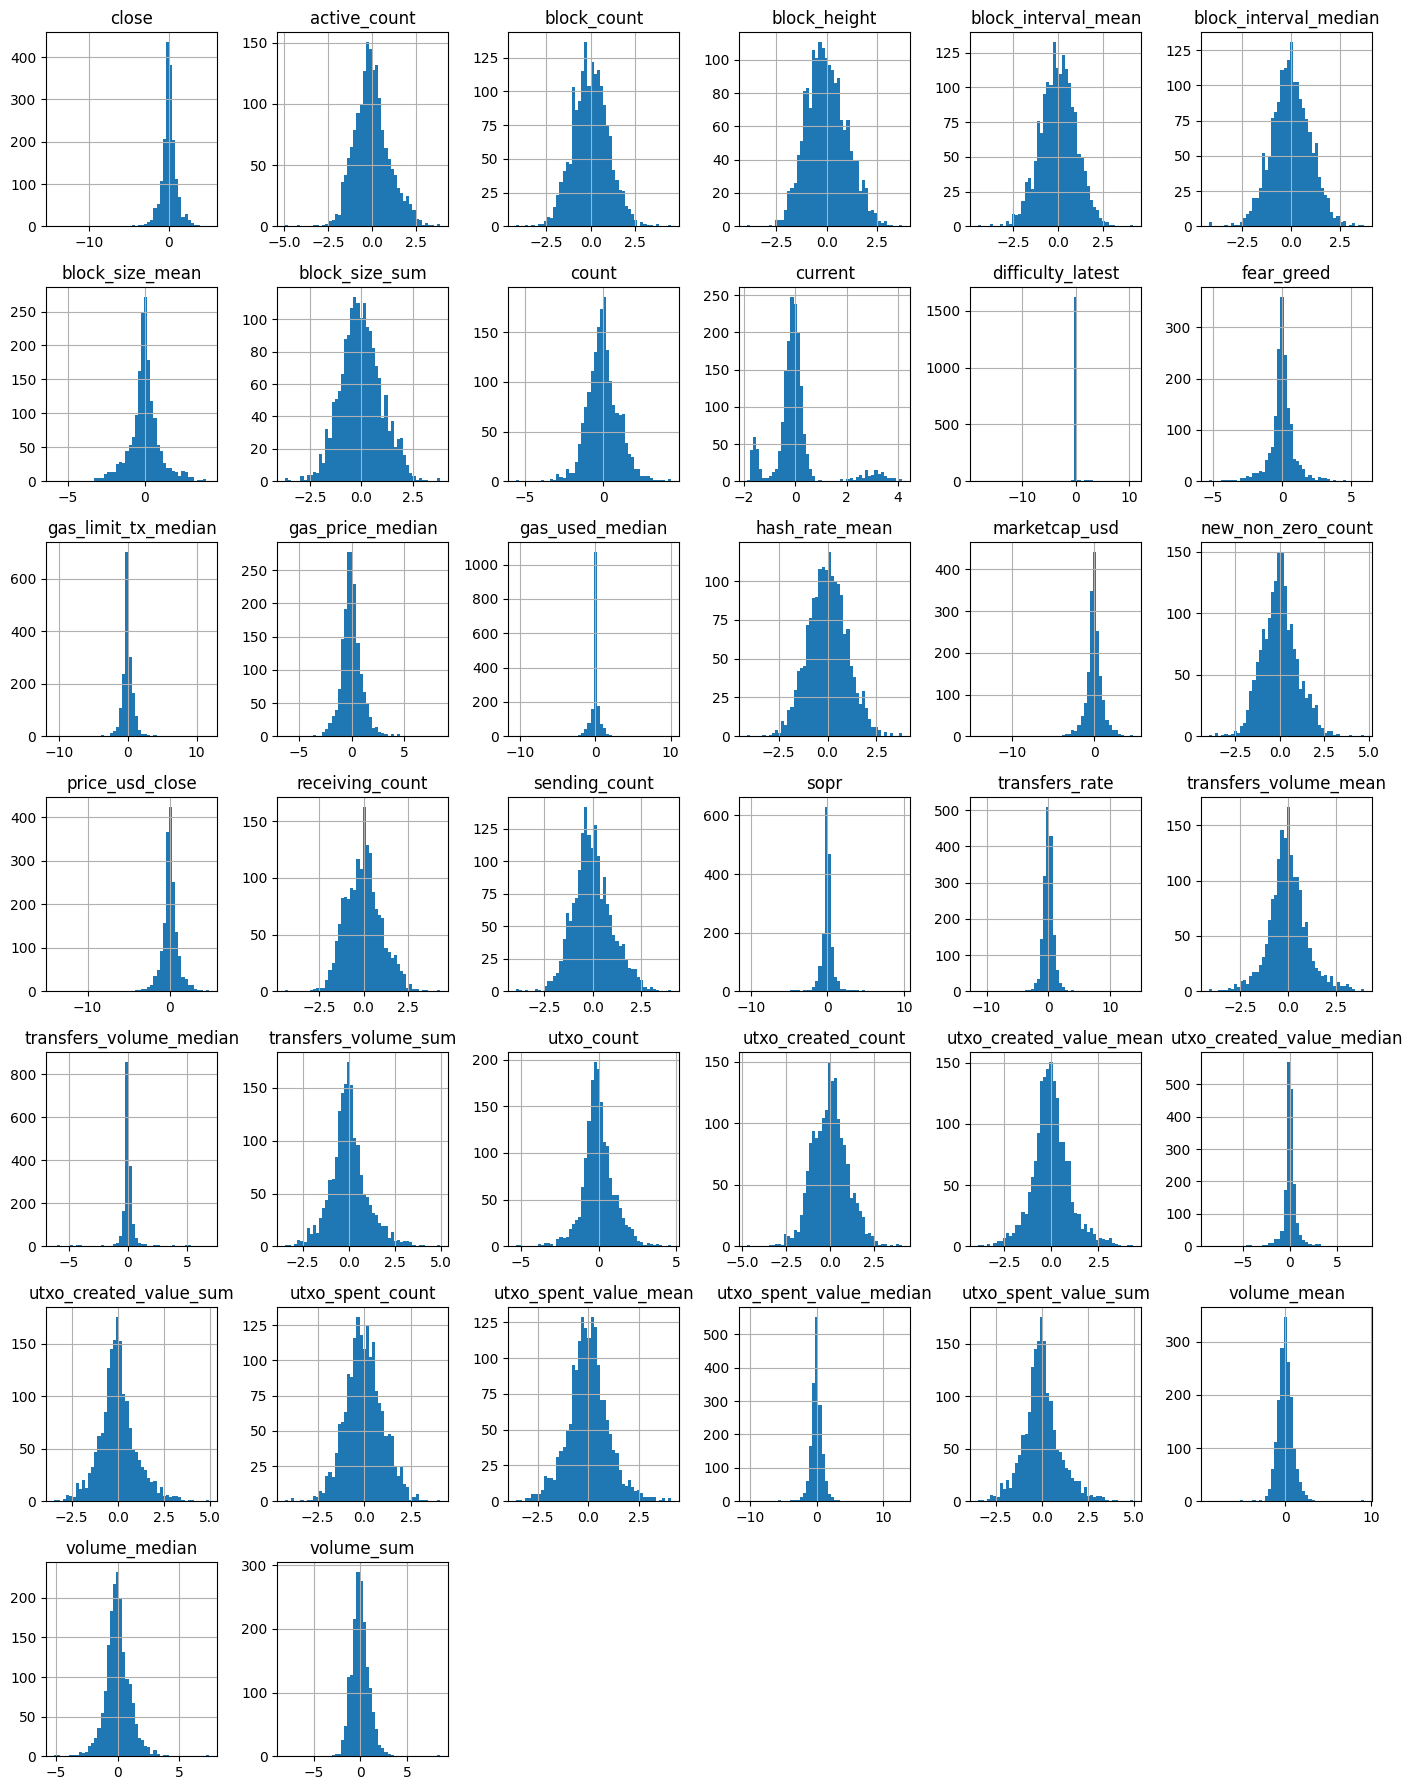

In [3]:
# 날짜를 제외한 컬럼 선택
btc_df_numeric = full_btc.select_dtypes(include='number')

# Z-score 계산
z_scores = stats.zscore(btc_df_numeric)

# Rank normalization 후 Z-score 계산
rank_normalized = btc_df_numeric.rank(method='average')
rank_z_scores = stats.zscore(rank_normalized)

# 분포 시각화
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(14, 18))

# Z-score 분포
pd.DataFrame(z_scores, columns=btc_df_numeric.columns).hist(ax=axes[1], bins=50)
axes[1].set_title('Z-score Distribution')

plt.title("Distribution of Z-scores")
plt.tight_layout()
plt.show()

특정 값(0) 에 너무 쏠린 분포나, 극단값을 가진 컬럼에 적절한 조치가 필요.  
전자는 30% 이상의 값이 동일한 값이라면 컬럼을 제거하고,  
후자는 양 끝단 1%씩 윈저라이징

In [4]:
# 데이터의 양 끝 1%를 winsorizing
def winsorize_series(series, limits):
    lower_limit = series.quantile(limits[0])
    upper_limit = series.quantile(1 - limits[1])
    return np.clip(series, lower_limit, upper_limit)

limits = [0.01, 0.01]
# 'close' 컬럼을 윈저라이징 대상에서 제외
columns_to_winsorize = btc_df_numeric.columns.difference(['close'])
winsorized_btc_df = btc_df_numeric.copy()
winsorized_btc_df[columns_to_winsorize] = btc_df_numeric[columns_to_winsorize].apply(winsorize_series, limits=limits)

# 컬럼별로 어떤 값이 전체 대비 30% 이상 차지하고 있다면 표시
for column in winsorized_btc_df.columns:
    value_counts = winsorized_btc_df[column].value_counts(normalize=True)
    dominant_values = value_counts[value_counts > 0.3]
    if not dominant_values.empty:
        print(f"Column '{column}' has values that constitute more than 30% of the total:")
        print(dominant_values)

Column 'difficulty_latest' has values that constitute more than 30% of the total:
difficulty_latest
0.0    0.927954
Name: proportion, dtype: float64


C:\Users\wklee\AppData\Local\Temp\ipykernel_16912\1454464834.py:15: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  filtered_btc_df.hist(ax=axes, bins=50)


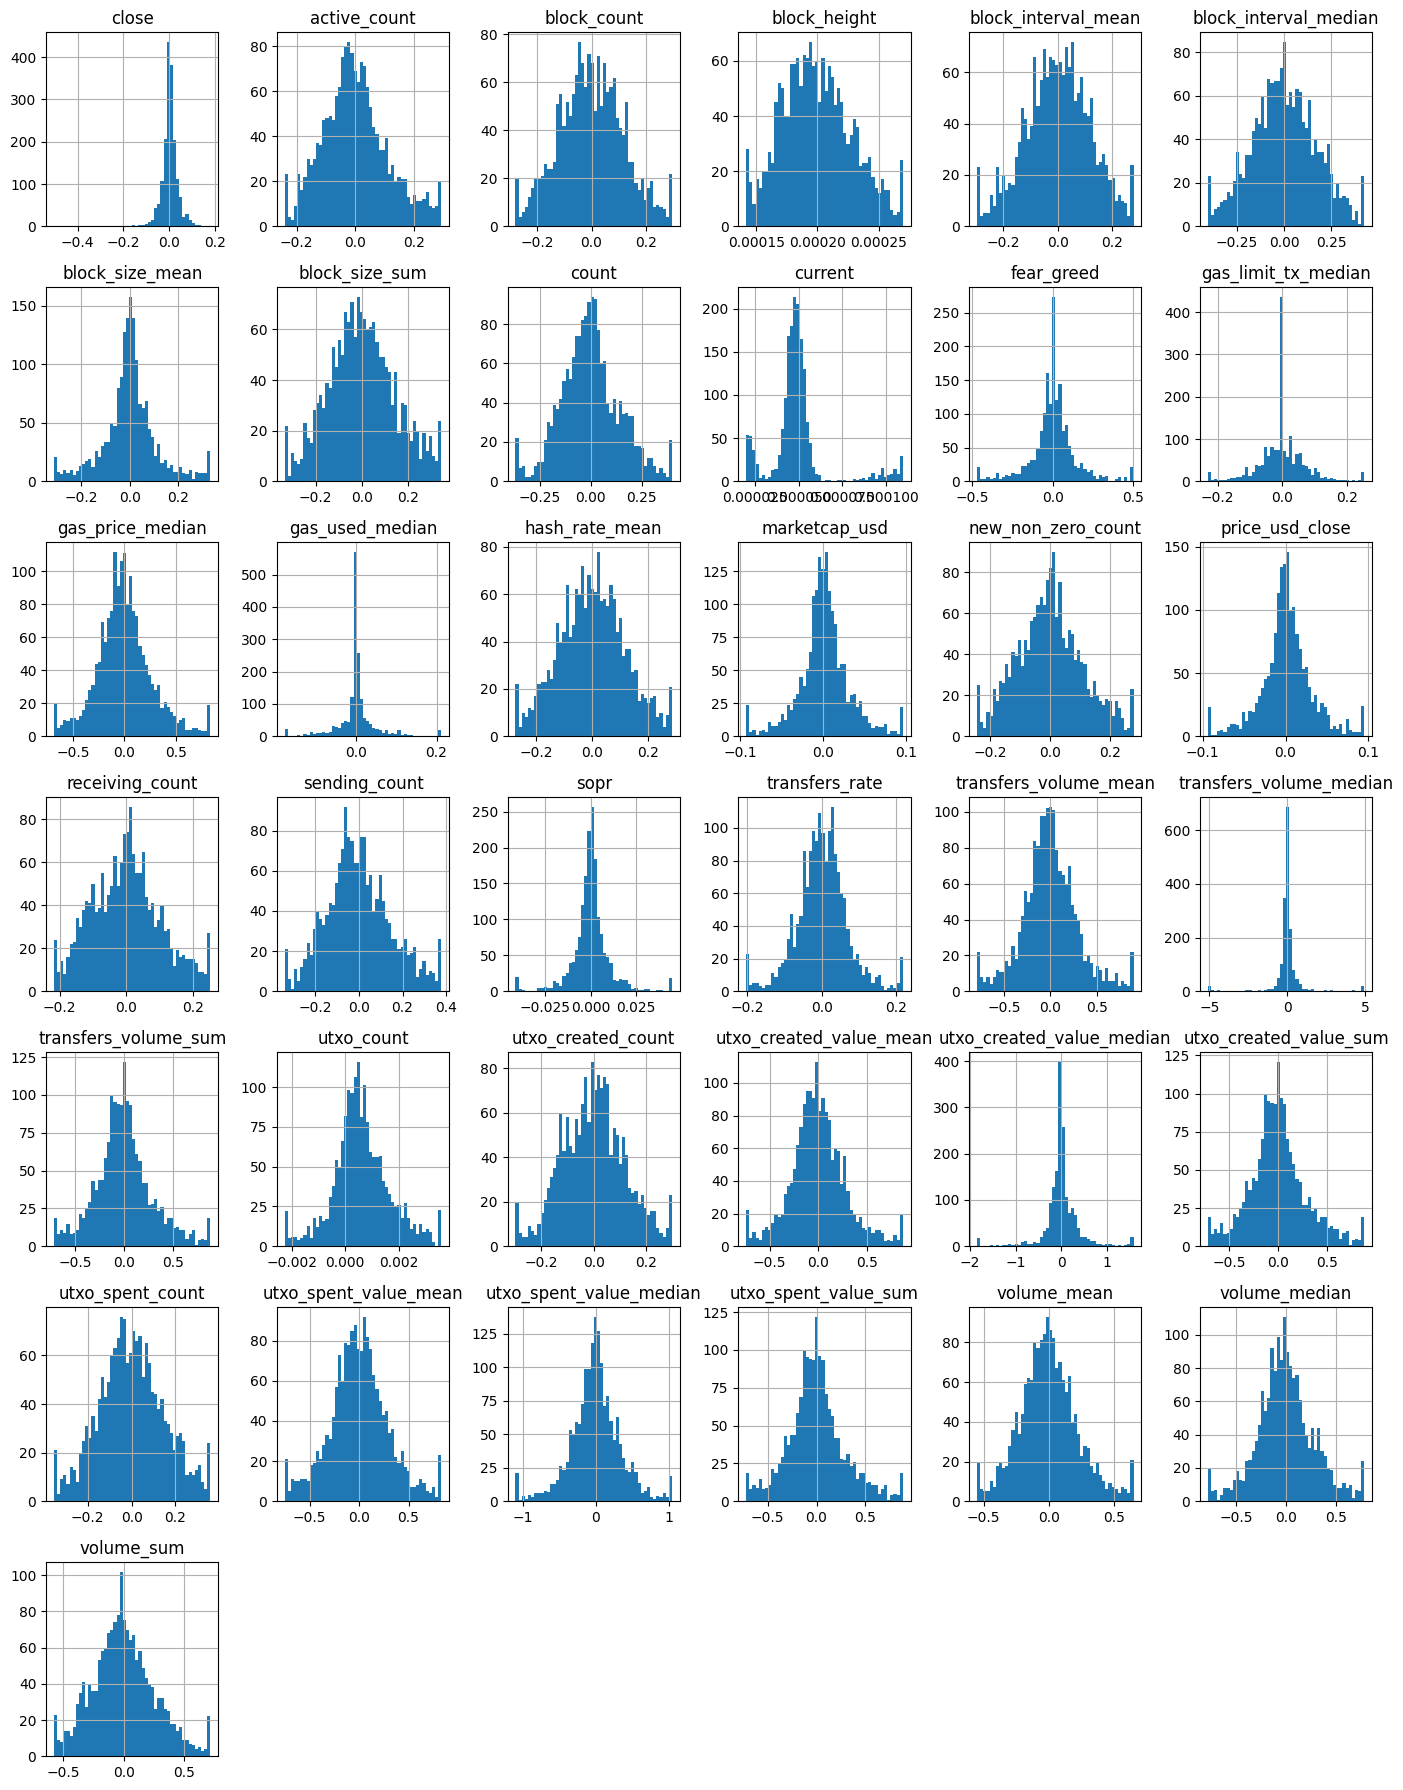

In [9]:
# 30% 이상 차지하는 컬럼 제거
columns_to_remove = []
for column in winsorized_btc_df.columns:
    value_counts = winsorized_btc_df[column].value_counts(normalize=True)
    dominant_values = value_counts[value_counts > 0.3]
    if not dominant_values.empty:
        columns_to_remove.append(column)

filtered_btc_df = winsorized_btc_df.drop(columns=columns_to_remove)

# 분포 시각화
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(14, 18))

# 필터링된 데이터 분포
filtered_btc_df.hist(ax=axes, bins=50)
axes.set_title('Filtered Data Distribution (Columns with >30% Dominant Values Removed)')

plt.tight_layout()
plt.show()

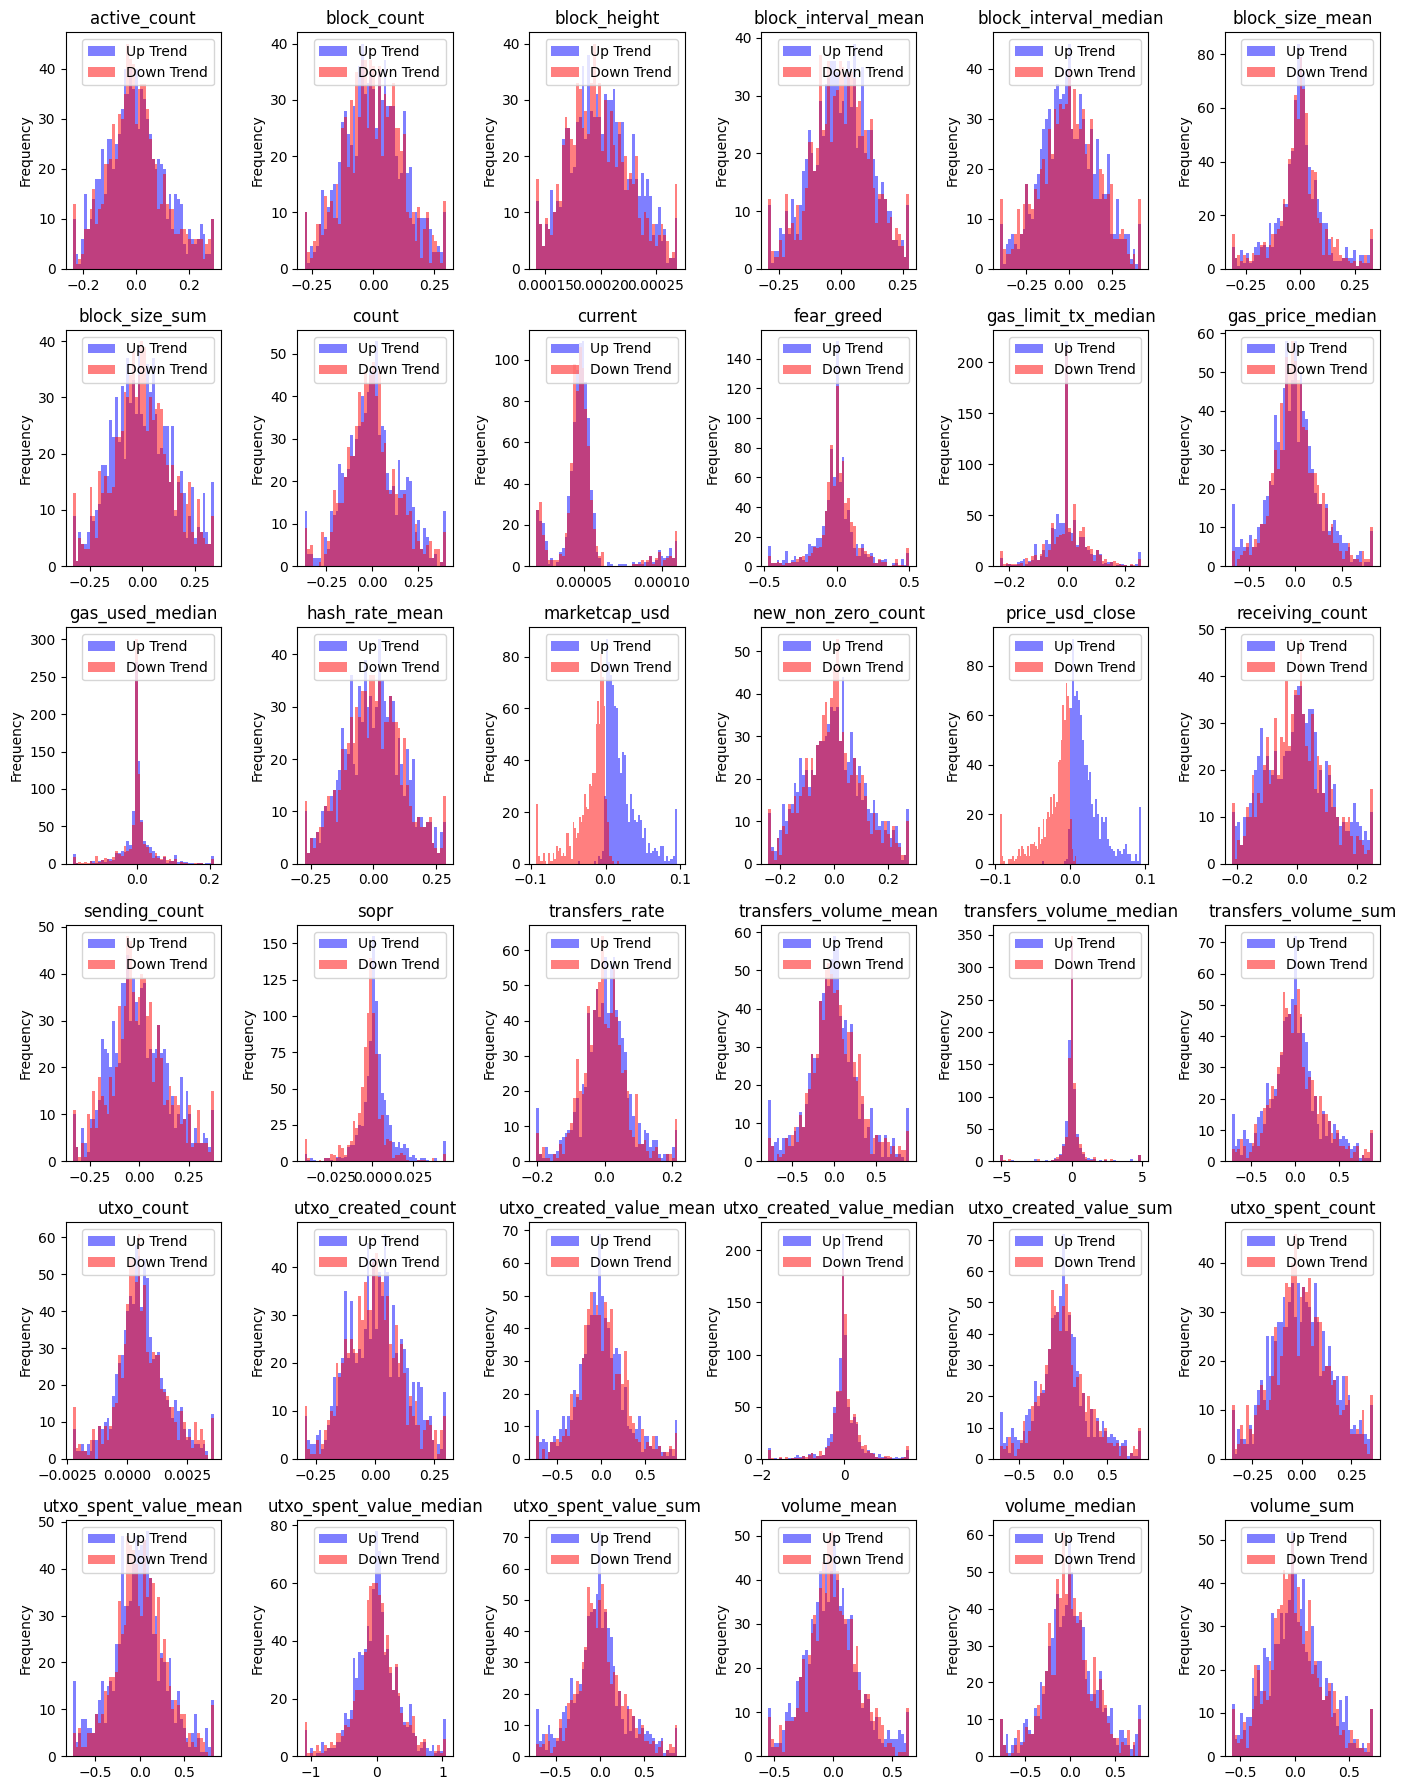

In [10]:
#  양수인 경우 'up', 음수인 경우 'down'으로 트렌드 설정
filtered_btc_df['trend'] = np.where(filtered_btc_df['close'] > 0, 'up', 'down')

# 트렌드에 따라 데이터 분리
up_trend_df = filtered_btc_df[filtered_btc_df['trend'] == 'up']
down_trend_df = filtered_btc_df[filtered_btc_df['trend'] == 'down']

# 'close' 와 'trend' 컬럼 제거
up_trend_df = up_trend_df.drop(columns=['close', 'trend'])
down_trend_df = down_trend_df.drop(columns=['close', 'trend'])

# 분포 시각화
ncols = 6
nrows = filtered_btc_df.shape[1] // ncols

fig, axes = plt.subplots(nrows=nrows , ncols=ncols, figsize=(14, 18))

for i, column in enumerate(up_trend_df.columns):
    ax = axes[i // ncols][i % ncols]
    up_trend_df[column].plot(kind='hist', ax=ax, bins=50, alpha=0.5, color='blue', label='Up Trend')
    down_trend_df[column].plot(kind='hist', ax=ax, bins=50, alpha=0.5, color='red', label='Down Trend')
    ax.set_title(f'{column}')
    ax.legend()

plt.tight_layout()
plt.show()

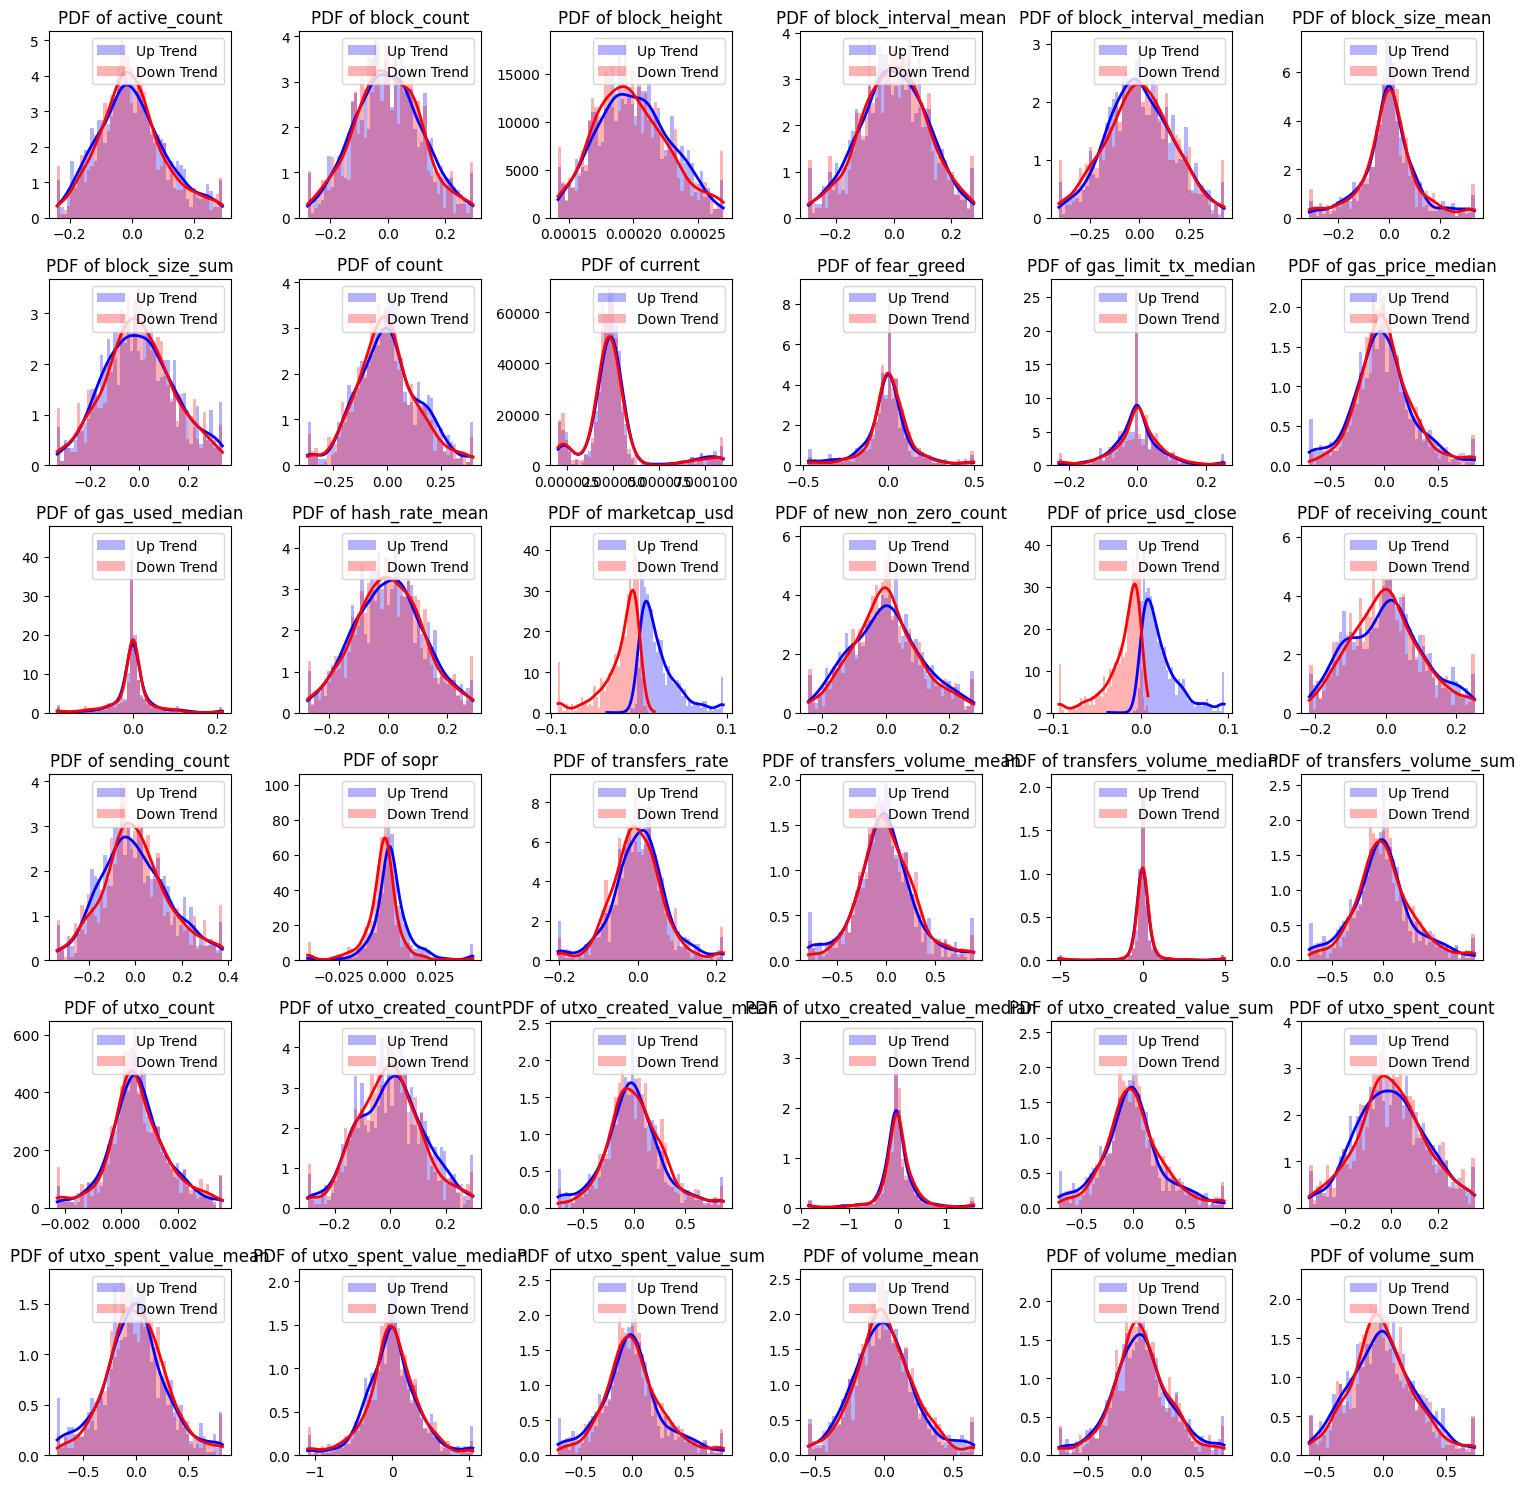

In [11]:
from scipy.stats import gaussian_kde

# 각 컬럼별로 trend에 따라 histogram으로부터 pdf 추정
ncols = 6
nrows = filtered_btc_df.shape[1] // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 15))
for i, column in enumerate(filtered_btc_df.columns.drop(['trend', 'close'])):
    ax = axes[i // ncols][i % ncols]
    
    # Up trend 데이터
    up_data = filtered_btc_df[filtered_btc_df['trend'] == 'up'][column].dropna()
    up_kde = gaussian_kde(up_data)
    x_up = np.linspace(up_data.min(), up_data.max(), 1000)
    
    # Down trend 데이터 
    down_data = filtered_btc_df[filtered_btc_df['trend'] == 'down'][column].dropna()
    down_kde = gaussian_kde(down_data)
    x_down = np.linspace(down_data.min(), down_data.max(), 1000)
    
    # 히스토그램과 KDE 플롯
    ax.hist(up_data, bins=50, density=True, alpha=0.3, color='blue', label='Up Trend')
    ax.hist(down_data, bins=50, density=True, alpha=0.3, color='red', label='Down Trend')
    ax.plot(x_up, up_kde(x_up), color='blue', linewidth=2)
    ax.plot(x_down, down_kde(x_down), color='red', linewidth=2)
    ax.set_title(f'PDF of {column}')
    ax.legend()

plt.tight_layout()
plt.show()

In [12]:
# 각 컬럼별로 Kolmogorov-Smirnov 테스트 수행
from scipy.stats import ks_2samp

ks_results = {}
for column in filtered_btc_df.columns.drop(['close', 'marketcap_usd', 'price_usd_close', 'trend']):
    # Up trend와 Down trend 데이터 추출
    up_data = filtered_btc_df[filtered_btc_df['trend'] == 'up'][column].dropna()
    down_data = filtered_btc_df[filtered_btc_df['trend'] == 'down'][column].dropna()
    
    # KS 테스트 수행
    statistic, pvalue = ks_2samp(up_data, down_data)
    ks_results[column] = {'statistic': statistic, 'p-value': pvalue}
    
# 결과 출력 (유의수준 5% 이내에서 유의한 컬럼만)
for column, result in ks_results.items():
    if result['p-value'] < 0.05:  # 유의수준 5%
        print(f"\n{column}:")
        print(f"KS 통계량: {result['statistic']:.4f}")
        print(f"p-value: {result['p-value']:.4e}")


fear_greed:
KS 통계량: 0.0666
p-value: 4.0148e-02

sopr:
KS 통계량: 0.2959
p-value: 5.4885e-34

transfers_rate:
KS 통계량: 0.0829
p-value: 4.7838e-03

utxo_created_value_median:
KS 통계량: 0.0985
p-value: 4.0394e-04


In [13]:
# 유의한 컬럼만 선택하여 새로운 데이터프레임 생성
significant_columns = [col for col, result in ks_results.items() if result['p-value'] < 0.05]
significant_columns.append('trend')  # trend 컬럼도 포함

# 유의한 컬럼으로만 구성된 데이터프레임 생성
significant_btc_df = filtered_btc_df[significant_columns].copy()

print("유의한 컬럼 수:", len(significant_columns)-1)  # trend 컬럼 제외
print("\n선택된 컬럼 목록:")
for col in significant_columns:
    if col != 'trend':
        print(f"- {col}")

유의한 컬럼 수: 4

선택된 컬럼 목록:
- fear_greed
- sopr
- transfers_rate
- utxo_created_value_median


KS-test에 의해 trend가 up일 때와 down일 때  
유의하게 구분되는 온체인 데이터가 위 4개로 선정됨.  

### 해야할 것 - 구해진 주요 온체인 데이터로 DAGs sampling 하기.

본래 논문 방법론의 DAGs sampling 방법을 따름.  
다만 선기님이 올려준 논문 "Dynamic evolution of causal relationships among cryptocurrencies" 에서는   
Bayesian Network를 이용해 인과관계를 분석하고 있음.     

두가지 모두 해본다.
=> 두가지 모두 같은 방법임. (FGES)

### FGES Method

In [20]:
# significant_btc_df = significant_btc_df.drop('trend', axis=1)

significant_btc_df

,fear_greed,sopr,transfers_rate,utxo_created_value_median
timestamp,,,,
2020-01-02,0.052644,-0.001002,0.090779,0.323330
2020-01-03,-0.025975,0.004284,0.212768,0.070417
2020-01-04,0.000000,-0.004853,0.030948,-0.232972
2020-01-05,0.025975,0.005598,-0.141365,-0.141330
2020-01-06,0.050010,0.001179,0.124629,0.430095
...,...,...,...,...
2024-09-27,0.198851,-0.000659,0.036659,0.368672
2024-09-28,0.048009,0.004405,-0.116683,-0.596819
2024-09-29,-0.015748,-0.012034,0.045909,-0.752359


In [86]:
import pandas as pd
from pgmpy.estimators import HillClimbSearch, BicScore
from pgmpy.models import BayesianNetwork
from sklearn.cluster import KMeans

# Load and preprocess data
def preprocess_data(data):
    # Normalize and discretize data
    data_normalized = (data - data.min()) / (data.max() - data.min())
    
    # 각 컬럼별로 KMeans 적용
    for col in data.columns:
        kmeans = KMeans(n_clusters=2)
        data[f'{col}_State'] = kmeans.fit_predict(data_normalized[col].values.reshape(-1, 1))
    
    return data

# Create BN model using structure learning
def create_bn_model(data):
    bn_model = HillClimbSearch(data).estimate(scoring_method=BicScore(data))
    return bn_model

# Analyze causal relationships
def analyze_relationships(bn_model):
    edges = bn_model.edges()
    for edge in edges:
        print(f"Causal link: {edge[0]} -> {edge[1]}")

essential_cols = ['close', 'fear_greed', 'sopr', 'transfers_rate', 'utxo_created_value_median']
essential_btc_df = filtered_btc_df[essential_cols].copy()

# Run preprocessing, BN construction, and analysis
preprocessed_data = preprocess_data(essential_btc_df)
bn_model = create_bn_model(preprocessed_data)
analyze_relationships(bn_model)

  0%|          | 3/1000000 [00:01<119:15:55,  2.33it/s]

Causal link: close_State -> sopr_State
Causal link: close_State -> transfers_rate_State
Causal link: fear_greed_State -> close_State


In [91]:
from pgmpy.estimators import HillClimbSearch, BicScore
from pgmpy.models import BayesianNetwork
import numpy as np
from sklearn.preprocessing import KBinsDiscretizer

def preprocess_data(df, n_bins=5, strategy='quantile'):
    """
    데이터 이산화 처리
    """
    # 인덱스 저장
    index = df.index
    
    # 이산화를 위한 빈 배열 생성
    discretized_values = np.zeros((len(df), len(df.columns)))
    
    # 각 컬럼별로 이산화 수행
    for i, col in enumerate(df.columns):
        discretizer = KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy=strategy)
        values = df[col].values.reshape(-1, 1)
        discretized_values[:, i] = discretizer.fit_transform(values).ravel()
    
    # 이산화된 값으로 새로운 데이터프레임 생성
    discretized_df = pd.DataFrame(
        discretized_values, 
        columns=df.columns,
        index=index
    )
    
    return discretized_df

def learn_multiple_dags(data, n_iterations=10):
    """
    여러 번의 구조 학습 시도
    """
    all_edges = []
    processed_data = preprocess_data(data)
    
    for i in range(n_iterations):
        # 데이터 부트스트래핑
        sample_indices = np.random.choice(len(processed_data), size=len(processed_data), replace=True)
        sample_data = processed_data.iloc[sample_indices]
        
        # BIC 스코어 계산 및 구조 학습
        hc = HillClimbSearch(sample_data)
        model = hc.estimate(
            scoring_method=BicScore(sample_data),
            max_iter=1000,
            black_list=None,
            white_list=None,
        )
        
        all_edges.extend(model.edges())
    
    # 빈도 기반 엣지 필터링
    edge_counts = {}
    for edge in all_edges:
        edge_counts[edge] = edge_counts.get(edge, 0) + 1
    
    # 일정 빈도 이상 나타난 엣지만 선택 (예: 20% 이상)
    threshold = n_iterations * 0.2
    significant_edges = [edge for edge, count in edge_counts.items() if count >= threshold]
    
    print(f"\n발견된 인과관계 (최소 {threshold}회 이상 발견):")
    for edge in significant_edges:
        print(f"{edge[0]} -> {edge[1]} (빈도: {edge_counts[edge]}/{n_iterations})")
    
    return significant_edges

essential_cols = ['close', 'fear_greed', 'sopr', 'transfers_rate', 'utxo_created_value_median']
essential_btc_df = filtered_btc_df[essential_cols].copy()
causal_edges = learn_multiple_dags(essential_btc_df, n_iterations=100)

  0%|          | 3/1000 [00:00<00:13, 75.30it/s]


발견된 인과관계 (최소 20.0회 이상 발견):
close -> sopr (빈도: 73/100)
transfers_rate -> utxo_created_value_median (빈도: 59/100)
utxo_created_value_median -> close (빈도: 45/100)
sopr -> close (빈도: 27/100)
close -> utxo_created_value_median (빈도: 23/100)
utxo_created_value_median -> transfers_rate (빈도: 33/100)


In [102]:
def create_lagged_data(df, lags=[1, 2, 3]):
    """
    데이터프레임에 지연된 변수들을 추가하는 함수
    """
    lagged_df = df[['close']].copy()  # close만 타겟으로 남기고
    
    # close를 제외한 나머지 변수들에 대해 lag 적용
    features = [col for col in df.columns if col != 'close']
    for col in features:
        for lag in lags:
            lagged_df[f'{col}_lag{lag}'] = df[col].shift(lag)
    
    return lagged_df.dropna()

def learn_multiple_dags_with_temporal_constraint(data, n_iterations=10, max_lag=5):
    """
    시간적 제약을 포함한 DAG 학습
    """
    all_edges = []
    processed_data = preprocess_data(data)
    
    # black_list 생성
    black_list = []
    
    # 1. close -> 과거 변수로 가는 모든 엣지 제한
    lagged_cols = [col for col in data.columns if 'lag' in col]
    for col in lagged_cols:
        black_list.append(('close', col))

    # 2. 더 이전 시점의 lag -> 최근 시점의 lag로 가는 엣지 제한
    base_features = list(set([col.split('_lag')[0] for col in lagged_cols]))
    for i in range(1, max_lag+1):
        for j in range(1, i):  # lag가 더 작은 값들
            for f_i in base_features:
                for f_j in base_features:
                    black_list.append((f'{f_j}_lag{j}', f'{f_i}_lag{i}'))
    
    print("제한된 엣지들:")
    for edge in black_list:
        print(f"{edge[0]} -> {edge[1]}")
    
    for i in range(n_iterations):
        sample_indices = np.random.choice(len(processed_data), size=len(processed_data), replace=True)
        sample_data = processed_data.iloc[sample_indices]
        
        hc = HillClimbSearch(sample_data)
        model = hc.estimate(
            scoring_method=BicScore(sample_data),
            max_iter=1000,
            black_list=black_list
        )
        
        all_edges.extend(model.edges())
    
    edge_counts = {}
    for edge in all_edges:
        edge_counts[edge] = edge_counts.get(edge, 0) + 1
    
    threshold = n_iterations * 0.2
    significant_edges = [edge for edge, count in edge_counts.items() if count >= threshold]
    
    print(f"\n발견된 인과관계 (최소 {threshold}회 이상 발견):")
    for edge in significant_edges:
        print(f"{edge[0]} -> {edge[1]} (빈도: {edge_counts[edge]}/{n_iterations})")
    
    return significant_edges

# 데이터 준비
essential_cols = ['close', 'fear_greed', 'sopr', 'transfers_rate', 'utxo_created_value_median']
essential_btc_df = filtered_btc_df[essential_cols].copy()

# 지연된 변수들이 포함된 데이터프레임 생성
lagged_df = create_lagged_data(essential_btc_df, lags=[1, 2, 3])

# 시간적 제약을 포함한 DAG 학습 실행
causal_edges = learn_multiple_dags_with_temporal_constraint(lagged_df, n_iterations=100)p

제한된 엣지들:
close -> fear_greed_lag1
close -> fear_greed_lag2
close -> fear_greed_lag3
close -> sopr_lag1
close -> sopr_lag2
close -> sopr_lag3
close -> transfers_rate_lag1
close -> transfers_rate_lag2
close -> transfers_rate_lag3
close -> utxo_created_value_median_lag1
close -> utxo_created_value_median_lag2
close -> utxo_created_value_median_lag3
fear_greed_lag1 -> fear_greed_lag2
utxo_created_value_median_lag1 -> fear_greed_lag2
transfers_rate_lag1 -> fear_greed_lag2
sopr_lag1 -> fear_greed_lag2
fear_greed_lag1 -> utxo_created_value_median_lag2
utxo_created_value_median_lag1 -> utxo_created_value_median_lag2
transfers_rate_lag1 -> utxo_created_value_median_lag2
sopr_lag1 -> utxo_created_value_median_lag2
fear_greed_lag1 -> transfers_rate_lag2
utxo_created_value_median_lag1 -> transfers_rate_lag2
transfers_rate_lag1 -> transfers_rate_lag2
sopr_lag1 -> transfers_rate_lag2
fear_greed_lag1 -> sopr_lag2
utxo_created_value_median_lag1 -> sopr_lag2
transfers_rate_lag1 -> sopr_lag2
sopr_lag1 -

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:23, 42.83it/s]


발견된 인과관계 (최소 200.0회 이상 발견):
fear_greed_lag2 -> fear_greed_lag1 (빈도: 1000/1000)
fear_greed_lag3 -> fear_greed_lag2 (빈도: 1000/1000)
sopr_lag2 -> sopr_lag1 (빈도: 1000/1000)
sopr_lag3 -> sopr_lag2 (빈도: 1000/1000)
transfers_rate_lag2 -> utxo_created_value_median_lag2 (빈도: 267/1000)
utxo_created_value_median_lag3 -> utxo_created_value_median_lag1 (빈도: 1000/1000)
utxo_created_value_median_lag3 -> transfers_rate_lag3 (빈도: 617/1000)
utxo_created_value_median_lag1 -> transfers_rate_lag1 (빈도: 872/1000)
utxo_created_value_median_lag2 -> transfers_rate_lag2 (빈도: 644/1000)
transfers_rate_lag3 -> utxo_created_value_median_lag3 (빈도: 266/1000)
utxo_created_value_median_lag3 -> utxo_created_value_median_lag2 (빈도: 332/1000)


In [103]:
causal_edges

[('fear_greed_lag2', 'fear_greed_lag1'),
 ('fear_greed_lag3', 'fear_greed_lag2'),
 ('sopr_lag2', 'sopr_lag1'),
 ('sopr_lag3', 'sopr_lag2'),
 ('transfers_rate_lag2', 'utxo_created_value_median_lag2'),
 ('utxo_created_value_median_lag3', 'utxo_created_value_median_lag1'),
 ('utxo_created_value_median_lag3', 'transfers_rate_lag3'),
 ('utxo_created_value_median_lag1', 'transfers_rate_lag1'),
 ('utxo_created_value_median_lag2', 'transfers_rate_lag2'),
 ('transfers_rate_lag3', 'utxo_created_value_median_lag3'),
 ('utxo_created_value_median_lag3', 'utxo_created_value_median_lag2')]